# How fast is the Bay of Bengal warming?

**Author:** MD Ratul Hasan Ripon · Oceanography, Shahjalal University of Science and Technology

This notebook measures how sea surface temperature (SST) in the Bay of Bengal has changed since 1982, using NOAA's satellite-based Optimum Interpolation SST dataset. It answers three questions:

1. **How fast** has the basin-average SST risen, and is the trend statistically significant?
2. **When in the year** is the warming strongest (winter, pre-monsoon, monsoon, post-monsoon)?
3. **Where** in the Bay is it warming fastest?

Everything runs from scratch: the notebook downloads only the Bay of Bengal subset of the data, so it takes a few minutes on Google Colab. The last section exports the figures and a results page for my portfolio website.

**Data:** NOAA OI SST V2 High Resolution (monthly means, 0.25° grid), provided by the NOAA Physical Sciences Laboratory, Boulder, Colorado, USA, from their website at https://psl.noaa.gov.

## 1. Setup

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q netCDF4

In [2]:
import json
import shutil
import string
import urllib.request
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)  # land cells are NaN

# Colours match my portfolio site
C = dict(primary="#123B3A", accent="#287C72", accent_light="#A9D3C6",
         earth="#C69B5B", text="#263A36", muted="#687B74", grid="#DCE5DF", land="#E6E2D6")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "xtick.color": C["muted"], "ytick.color": C["muted"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "legend.frameon": False,
})

## 2. Settings

The study box covers the open Bay of Bengal, from Sri Lanka (5°N) to the Bangladesh coast (23°N) and from the Indian coast (80°E) to Myanmar (95°E). Land cells have no SST value, so they drop out automatically.

The baseline for anomalies is 1991–2020, the current World Meteorological Organization climate normal.

In [3]:
LAT_MIN, LAT_MAX = 5.0, 23.0
LON_MIN, LON_MAX = 80.0, 95.0
START_YEAR, END_YEAR = 1982, 2025      # incomplete final years are dropped automatically
BASE_START, BASE_END = 1991, 2020

LOCAL_FILE = None                       # optional: path to an already-downloaded sst.mon.mean.nc
DATA_DIR = Path("data")
OUT_DIR = Path("output")
FIG_DIR = OUT_DIR / "figures"
SITE_DIR = OUT_DIR / "website" / "bay-of-bengal-sst"
for d in (DATA_DIR, FIG_DIR, SITE_DIR / "figures", SITE_DIR / "data"):
    d.mkdir(parents=True, exist_ok=True)

GITHUB_REPO = "https://github.com/ratulripon/bay-of-bengal-sst"
COLAB_URL = "https://colab.research.google.com/github/ratulripon/bay-of-bengal-sst/blob/main/bay_of_bengal_sst.ipynb"

## 3. Download the data

The notebook asks NOAA's server for the Bay of Bengal subset only (a few MB rather than the full global file). It tries OPeNDAP first and falls back to the NetCDF Subset Service. The subset is cached in `data/`, so re-running is instant.

In [4]:
OPENDAP_URL = "https://psl.noaa.gov/thredds/dodsC/Datasets/noaa.oisst.v2.highres/sst.mon.mean.nc"
NCSS_URL = (
    "https://psl.noaa.gov/thredds/ncss/grid/Datasets/noaa.oisst.v2.highres/sst.mon.mean.nc"
    f"?var=sst&north={LAT_MAX}&south={LAT_MIN}&west={LON_MIN}&east={LON_MAX}"
    f"&time_start={START_YEAR}-01-01T00:00:00Z&time_end={END_YEAR}-12-31T23:59:59Z&accept=netcdf"
)
CACHE = DATA_DIR / f"oisst_bay_of_bengal_{START_YEAR}_{END_YEAR}.nc"


def subset(ds):
    lat = slice(LAT_MIN, LAT_MAX) if ds.lat[0] < ds.lat[-1] else slice(LAT_MAX, LAT_MIN)
    ds = ds.sel(lat=lat, lon=slice(LON_MIN, LON_MAX),
                time=slice(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31"))
    out = ds[["sst"]].sortby("lat")
    # NOAA's global attributes can clash when re-saved, so keep a short clean set
    out.attrs = {"title": "NOAA OI SST V2 High Resolution, monthly mean, Bay of Bengal subset",
                 "source": OPENDAP_URL}
    return out


if CACHE.exists():
    print("Using cached file", CACHE)
elif LOCAL_FILE:
    with xr.open_dataset(LOCAL_FILE) as src:
        subset(src).load().to_netcdf(CACHE)
else:
    try:
        print("Downloading via OPeNDAP ...")
        with xr.open_dataset(OPENDAP_URL) as src:
            subset(src).load().to_netcdf(CACHE)
    except Exception as err:
        print("OPeNDAP failed:", err, "\nTrying the NetCDF Subset Service ...")
        tmp = DATA_DIR / "ncss_download.nc"
        urllib.request.urlretrieve(NCSS_URL, tmp)
        with xr.open_dataset(tmp) as src:
            subset(src).load().to_netcdf(CACHE)
        tmp.unlink()

ACCESS_DATE = date.today().isoformat()
sst = xr.open_dataset(CACHE)["sst"].load()
print(sst.dims, dict(sst.sizes))
print("Time:", str(sst.time.values[0])[:7], "to", str(sst.time.values[-1])[:7])
print(f"Grid: {sst.lat.size} x {sst.lon.size} cells, "
      f"{int(np.isfinite(sst.isel(time=0)).sum())} ocean cells")

Using cached file data/oisst_bay_of_bengal_1982_2025.nc
('time', 'lat', 'lon') {'time': 528, 'lat': 72, 'lon': 60}
Time: 1982-01 to 2025-12
Grid: 72 x 60 cells, 3402 ocean cells


## 4. Basin-average SST

Grid cells get smaller towards the poles, so each cell is weighted by the cosine of its latitude before averaging. Years without all 12 months are dropped.

In [5]:
weights = np.cos(np.deg2rad(sst.lat))
basin = sst.weighted(weights).mean(("lat", "lon")).to_series().astype(float)
basin.index = pd.DatetimeIndex(basin.index).to_period("M").to_timestamp()
basin.name = "sst"

months_per_year = basin.groupby(basin.index.year).count()
FULL_YEARS = months_per_year[months_per_year == 12].index.to_numpy()
basin = basin[basin.index.year.isin(FULL_YEARS)]
assert basin.notna().all(), "missing months in the basin average"

FIRST, LAST = int(FULL_YEARS.min()), int(FULL_YEARS.max())
N_YEARS = len(FULL_YEARS)
print(f"{N_YEARS} complete years: {FIRST}-{LAST}")
print(f"Mean SST {basin.mean():.2f} °C, monthly range {basin.min():.2f} to {basin.max():.2f} °C")

44 complete years: 1982-2025
Mean SST 28.50 °C, monthly range 26.47 to 30.80 °C


## 5. Seasonal cycle and anomalies

The climatology is the average SST for each calendar month over 1991–2020. Subtracting it removes the seasonal cycle and leaves the **anomaly**: how much warmer or cooler a month was than normal.

In [6]:
base = basin[(basin.index.year >= BASE_START) & (basin.index.year <= BASE_END)]
clim = base.groupby(base.index.month).mean()
anom = basin - clim.reindex(basin.index.month).to_numpy()
anom.name = "anomaly"

annual = basin.groupby(basin.index.year).mean()
annual_anom = annual - base.groupby(base.index.year).mean().mean()

monthly_table = pd.DataFrame({"year": basin.index.year, "month": basin.index.month,
                              "sst_c": basin.round(3).to_numpy(),
                              "anomaly_c": anom.round(3).to_numpy()})
monthly_table.to_csv(SITE_DIR / "data" / "bay_of_bengal_sst_monthly.csv", index=False)

print("Climatology (°C):", clim.round(2).to_dict())
print("Warmest years:", annual.sort_values(ascending=False).head(5).round(2).to_dict())

Climatology (°C): {1: 27.0, 2: 27.22, 3: 28.25, 4: 29.51, 5: 29.69, 6: 29.24, 7: 28.78, 8: 28.53, 9: 28.66, 10: 28.87, 11: 28.47, 12: 27.62}
Warmest years: {2024: 29.22, 2016: 28.96, 2025: 28.96, 2021: 28.94, 2020: 28.93}


## 6. Trend test

I estimate the trend on **annual means**, which removes the seasonal cycle and reduces month-to-month autocorrelation.

- **Sen's slope** (Theil–Sen estimator): the median of all pairwise slopes, robust to outlier years such as strong El Niño years.
- **Mann–Kendall test**: a non-parametric test for a monotonic trend (Kendall's tau against time).
- **Ordinary least squares** is shown as a cross-check.

In [7]:
def trend_stats(years, values):
    years = np.asarray(years, float)
    values = np.asarray(values, float)
    sen = stats.theilslopes(values, years, 0.95)
    ols = stats.linregress(years, values)
    tcrit = stats.t.ppf(0.975, len(years) - 2)
    tau, p_mk = stats.kendalltau(years, values)
    return {
        "sen_per_decade": sen[0] * 10, "sen_low": sen[2] * 10, "sen_high": sen[3] * 10,
        "sen_intercept": sen[1],
        "ols_per_decade": ols.slope * 10,
        "ols_low": (ols.slope - tcrit * ols.stderr) * 10,
        "ols_high": (ols.slope + tcrit * ols.stderr) * 10,
        "ols_p": ols.pvalue, "r2": ols.rvalue ** 2,
        "mk_tau": tau, "mk_p": p_mk, "n": len(years),
    }


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


trend = trend_stats(annual.index, annual.values)
total_change = trend["sen_per_decade"] / 10 * (LAST - FIRST)

print(f"Sen's slope: {trend['sen_per_decade']:+.3f} °C/decade "
      f"(95% CI {trend['sen_low']:+.3f} to {trend['sen_high']:+.3f})")
print(f"Mann-Kendall: tau = {trend['mk_tau']:.2f}, {fmt_p(trend['mk_p'])}")
print(f"OLS: {trend['ols_per_decade']:+.3f} °C/decade "
      f"(95% CI {trend['ols_low']:+.3f} to {trend['ols_high']:+.3f}), R² = {trend['r2']:.2f}")
print(f"Change over {FIRST}-{LAST}: {total_change:+.2f} °C")

Sen's slope: +0.202 °C/decade (95% CI +0.153 to +0.239)
Mann-Kendall: tau = 0.63, p < 0.001
OLS: +0.188 °C/decade (95% CI +0.145 to +0.231), R² = 0.65
Change over 1982-2025: +0.87 °C


## 7. Which season warms fastest?

The Bay of Bengal's year is shaped by the monsoon, so I split it into four seasons. December is counted with the following January and February, so each winter is complete.

In [8]:
SEASONS = {
    "Winter (Dec–Feb)": [12, 1, 2],
    "Pre-monsoon (Mar–May)": [3, 4, 5],
    "Monsoon (Jun–Sep)": [6, 7, 8, 9],
    "Post-monsoon (Oct–Nov)": [10, 11],
}
df = basin.to_frame()
df["season_year"] = df.index.year + (df.index.month == 12)

season_rows = []
for name, months in SEASONS.items():
    sub = df[df.index.month.isin(months)]
    grouped = sub.groupby("season_year")["sst"].agg(["mean", "count"])
    grouped = grouped[grouped["count"] == len(months)]
    t = trend_stats(grouped.index, grouped["mean"])
    season_rows.append({"season": name, **t})

season_trends = pd.DataFrame(season_rows).set_index("season")
season_trends[["sen_per_decade", "sen_low", "sen_high", "mk_p", "n"]].round(3)

,sen_per_decade,sen_low,sen_high,mk_p,n
season,,,,,
Winter (Dec–Feb),0.183,0.130,0.246,0.0,43
Pre-monsoon (Mar–May),0.177,0.122,0.232,0.0,44
Monsoon (Jun–Sep),0.211,0.145,0.264,0.0,44
Post-monsoon (Oct–Nov),0.199,0.147,0.250,0.0,44


## 8. Where is it warming fastest?

The same calculation for every 0.25° grid cell: an OLS trend of annual mean SST, with a t-test on the slope. Cells with a significant trend (p < 0.05) are dotted on the map.

In [9]:
grid_annual = (sst.sel(time=sst.time.dt.year.isin(FULL_YEARS))
                  .groupby("time.year").mean())
Y = grid_annual.values                      # (year, lat, lon)
t = grid_annual.year.values.astype(float)
tc = t - t.mean()
sxx = (tc ** 2).sum()
slope = np.tensordot(tc, Y - Y.mean(0), axes=(0, 0)) / sxx
resid = Y - (Y.mean(0) + slope * tc[:, None, None])
se = np.sqrt((resid ** 2).sum(0) / (len(t) - 2) / sxx)
pval = 2 * stats.t.sf(np.abs(slope / se), len(t) - 2)

trend_map = xr.DataArray(slope * 10, coords={"lat": sst.lat, "lon": sst.lon}, dims=("lat", "lon"))
p_map = xr.DataArray(pval, coords=trend_map.coords, dims=trend_map.dims)
ocean = np.isfinite(trend_map)
w2d = (np.cos(np.deg2rad(trend_map.lat)) * xr.ones_like(trend_map)).where(ocean)


def area_mean(field, mask=True):
    m = ocean & mask
    return float((field.where(m) * w2d).sum() / w2d.where(m).sum())


sig_warming_pct = 100 * area_mean(((p_map < 0.05) & (trend_map > 0)).astype(float))
north = area_mean(trend_map, trend_map.lat >= 15)
south = area_mean(trend_map, trend_map.lat < 15)
print(f"Grid-cell trends: {float(trend_map.min()):+.3f} to {float(trend_map.max()):+.3f} °C/decade")
print(f"Ocean area with significant warming: {sig_warming_pct:.0f}%")
print(f"Mean trend north of 15°N: {north:+.3f}, south of 15°N: {south:+.3f} °C/decade")

Grid-cell trends: +0.076 to +0.257 °C/decade
Ocean area with significant warming: 100%
Mean trend north of 15°N: +0.195, south of 15°N: +0.185 °C/decade


## 9. Figures

In [10]:
WEB_FIGS = {}


def save(fig, name, alt, caption):
    png = FIG_DIR / f"{name}.png"
    fig.savefig(png, facecolor="white")
    from PIL import Image                    # Pillow comes with matplotlib
    img = Image.open(png).convert("RGB")
    img.thumbnail((1600, 1600))              # web-sized copy
    target = SITE_DIR / "figures" / f"{name}.webp"
    try:
        img.save(target, "WEBP", quality=85)
    except Exception:                        # Pillow built without WebP support
        target = target.with_suffix(".png")
        img.save(target)
    w, h = img.size
    WEB_FIGS[name] = {"file": f"figures/{target.name}", "w": w, "h": h, "alt": alt, "caption": caption}
    plt.show()


# name: (lon, lat, alignment); a label is drawn only if that point is land in the data
LAND_LABELS = {"India": (83.0, 19.5, "center"), "Bangladesh": (90.3, 22.8, "center"),
               "Myanmar": (94.9, 20.5, "right"), "Sri Lanka": (80.1, 7.4, "left")}


def map_axes(ax):
    ax.set_facecolor(C["land"])
    ax.grid(False)
    ax.set_aspect(1 / np.cos(np.deg2rad((LAT_MIN + LAT_MAX) / 2)))
    ax.set_xlim(float(sst.lon.min()) - 0.125, float(sst.lon.max()) + 0.125)
    ax.set_ylim(float(sst.lat.min()) - 0.125, float(sst.lat.max()) + 0.125)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}°E")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}°N")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(C["grid"])
    land = ~np.isfinite(sst.isel(time=0))
    for label, (x, y, ha) in LAND_LABELS.items():
        try:
            if bool(land.sel(lon=x, lat=y, method="nearest")):
                ax.text(x, y, label, ha=ha, va="center", fontsize=9,
                        color=C["muted"], style="italic")
        except Exception:
            pass

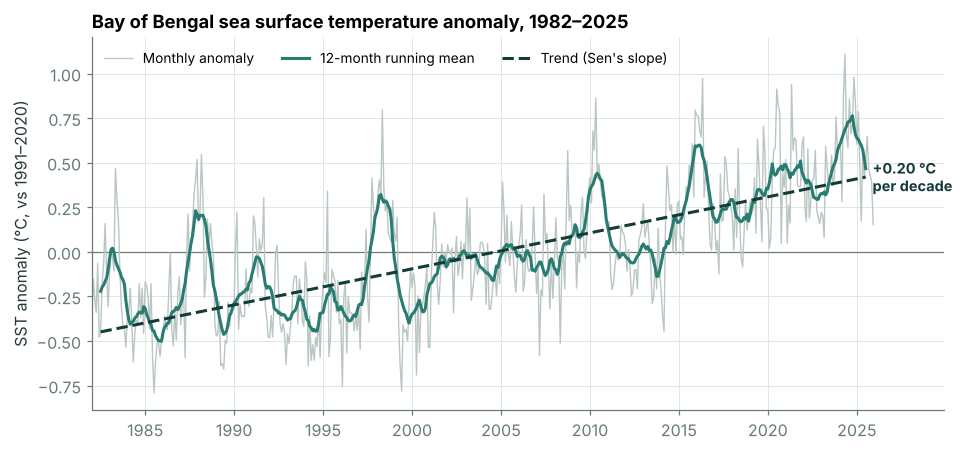

In [11]:
# 9a. Time series of monthly anomalies with the trend
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.axhline(0, color=C["muted"], lw=0.8)
ax.plot(anom.index, anom.values, color="#B9C6C1", lw=0.9, label="Monthly anomaly")
roll = anom.rolling(12, center=True).mean()
ax.plot(roll.index, roll.values, color=C["accent"], lw=2, label="12-month running mean")
mid = pd.to_datetime([f"{y}-07-01" for y in annual.index])
line = trend["sen_intercept"] + trend["sen_per_decade"] / 10 * annual.index.to_numpy()
offset = annual.mean() - annual_anom.mean()
ax.plot(mid, line - offset, color=C["primary"], lw=2, ls="--", label="Trend (Sen's slope)")
ax.text(mid[-1], (line - offset)[-1], f"  {trend['sen_per_decade']:+.2f} °C\n  per decade",
        va="center", ha="left", color=C["primary"], fontsize=9.5, fontweight="bold")
ax.set_xlim(anom.index[0], anom.index[-1] + pd.DateOffset(years=4))
ax.set_ylabel(f"SST anomaly (°C, vs {BASE_START}–{BASE_END})")
ax.set_title(f"Bay of Bengal sea surface temperature anomaly, {FIRST}–{LAST}")
ax.legend(loc="upper left", ncol=3, fontsize=9)
save(fig, "sst_anomaly_timeseries",
     f"Line chart of monthly Bay of Bengal SST anomalies from {FIRST} to {LAST} with a rising trend line",
     f"Basin-average SST anomaly relative to {BASE_START}–{BASE_END}. Grey: monthly values. "
     f"Teal: 12-month running mean. Dashed: Sen's slope trend fitted to annual means.")

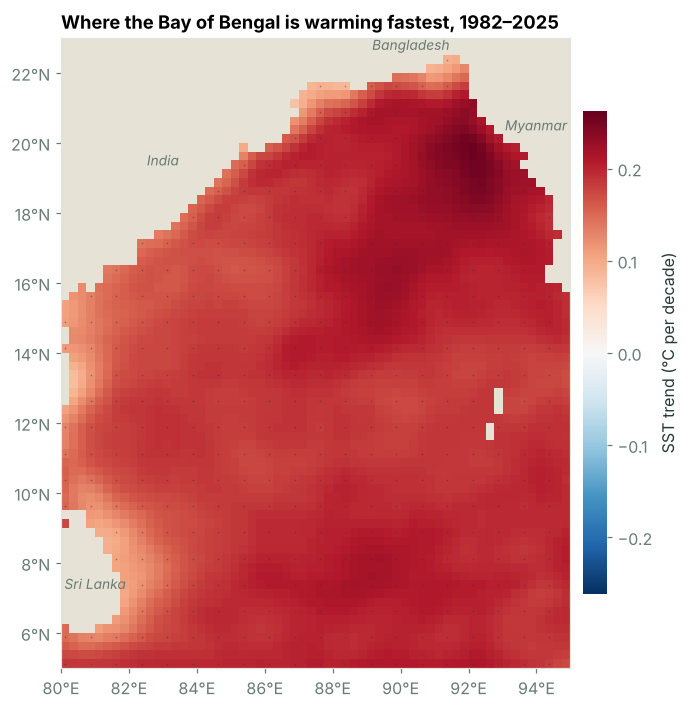

In [12]:
# 9b. Map of the warming trend
vmax = float(np.nanmax(np.abs(trend_map))) * 1.02
fig, ax = plt.subplots(figsize=(7.2, 7.6))
mesh = ax.pcolormesh(trend_map.lon, trend_map.lat, trend_map, cmap="RdBu_r",
                     vmin=-vmax, vmax=vmax, shading="nearest")
sig = (p_map < 0.05) & ocean
yy, xx = np.meshgrid(trend_map.lat, trend_map.lon, indexing="ij")
step = 3                                        # thin the dots so the colours stay readable
mask = sig.values[::step, ::step]
ax.scatter(xx[::step, ::step][mask], yy[::step, ::step][mask], s=1.2, c=C["text"], alpha=0.45, lw=0)
map_axes(ax)
cb = fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("SST trend (°C per decade)")
cb.outline.set_visible(False)
ax.set_title(f"Where the Bay of Bengal is warming fastest, {FIRST}–{LAST}")
save(fig, "sst_trend_map",
     "Map of the Bay of Bengal coloured by SST trend in degrees Celsius per decade",
     "Linear trend of annual mean SST in each 0.25° grid cell. Dots mark cells where the trend "
     "is statistically significant (p < 0.05). Land is shown in beige.")

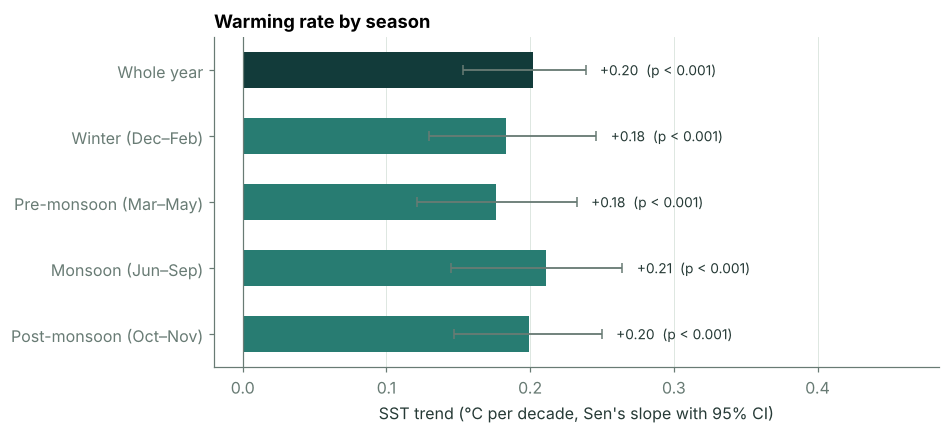

In [13]:
# 9c. Trend by season
order = list(SEASONS)
rows = season_trends.loc[order]
labels = ["Whole year"] + order
vals = [trend["sen_per_decade"]] + rows["sen_per_decade"].tolist()
lows = [trend["sen_low"]] + rows["sen_low"].tolist()
highs = [trend["sen_high"]] + rows["sen_high"].tolist()
ps = [trend["mk_p"]] + rows["mk_p"].tolist()

fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.set_axisbelow(True)
y = np.arange(len(labels))[::-1]
colors = [C["primary"]] + [C["accent"]] * len(order)
ax.barh(y, vals, height=0.55, color=colors)
ax.errorbar(vals, y, xerr=[np.subtract(vals, lows), np.subtract(highs, vals)],
            fmt="none", ecolor=C["muted"], elinewidth=1.2, capsize=3)
for yi, v, hi, p in zip(y, vals, highs, ps):
    ax.text(max(hi, v) + 0.01, yi, f"{v:+.2f}  ({fmt_p(p)})", va="center", fontsize=9, color=C["text"])
ax.set_yticks(y, labels)
ax.axvline(0, color=C["muted"], lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlim(min(0, min(lows)) - 0.02, max(highs) + 0.22)
ax.set_xlabel("SST trend (°C per decade, Sen's slope with 95% CI)")
ax.set_title("Warming rate by season")
save(fig, "sst_trend_by_season",
     "Bar chart comparing the SST warming rate across the four Bay of Bengal seasons",
     "Sen's slope of seasonal mean SST, with 95% confidence intervals and Mann–Kendall p-values.")

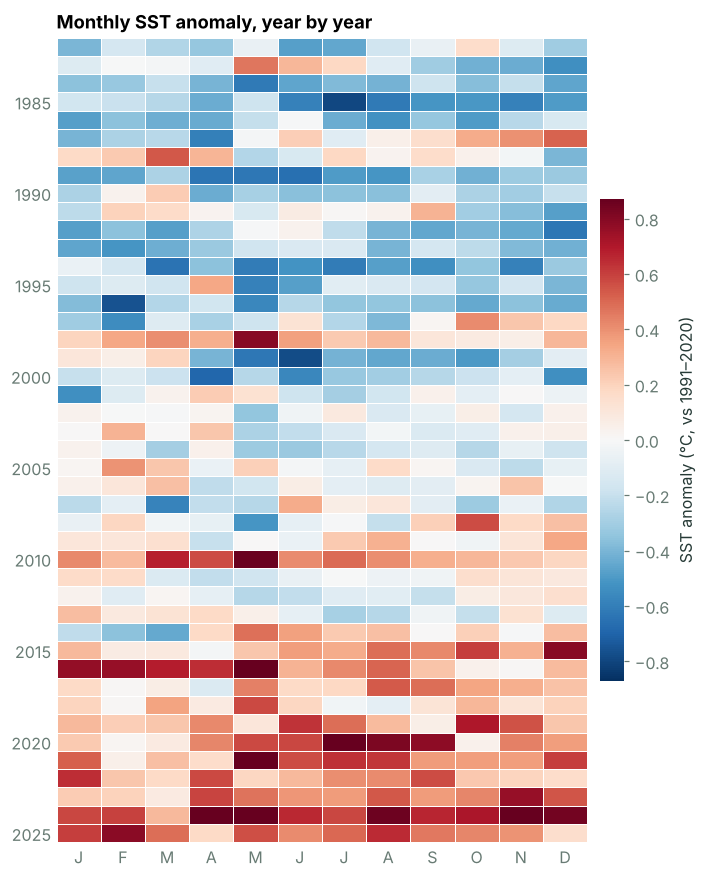

In [14]:
# 9d. Year-by-month anomaly heatmap
grid = monthly_table.pivot(index="year", columns="month", values="anomaly_c")
lim = float(np.nanpercentile(np.abs(grid.values), 99))
fig, ax = plt.subplots(figsize=(7.5, 9.5))
mesh = ax.pcolormesh(np.arange(1, 13), grid.index, grid.values, cmap="RdBu_r",
                     vmin=-lim, vmax=lim, shading="nearest", edgecolors="white", linewidth=0.4)
ax.invert_yaxis()
ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
ax.set_yticks([y for y in grid.index if y % 5 == 0])
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02)
cb.set_label(f"SST anomaly (°C, vs {BASE_START}–{BASE_END})")
cb.outline.set_visible(False)
ax.set_title("Monthly SST anomaly, year by year")
save(fig, "sst_anomaly_heatmap",
     "Heatmap of monthly SST anomalies with years as rows and months as columns",
     "Each cell is one month's basin-average anomaly. Blue months were cooler than the "
     f"{BASE_START}–{BASE_END} normal, red months warmer.")

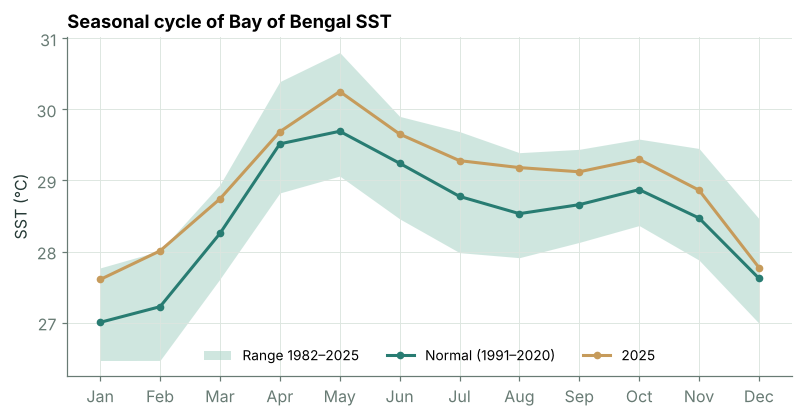

In [15]:
# 9e. Seasonal cycle
by_month = monthly_table.pivot(index="year", columns="month", values="sst_c")
m = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.fill_between(m, by_month.min(), by_month.max(), color=C["accent_light"], alpha=0.55, lw=0,
                label=f"Range {FIRST}–{LAST}")
ax.plot(m, clim.values, color=C["accent"], lw=2, marker="o", ms=4,
        label=f"Normal ({BASE_START}–{BASE_END})")
ax.plot(m, by_month.loc[LAST].values, color=C["earth"], lw=2, marker="o", ms=4, label=str(LAST))
ax.set_xticks(m, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("SST (°C)")
ax.set_title("Seasonal cycle of Bay of Bengal SST")
ax.legend(loc="lower center", ncol=3, fontsize=9)
save(fig, "sst_seasonal_cycle",
     "Line chart of the Bay of Bengal's average SST in each month of the year",
     f"Monthly basin-average SST: the {BASE_START}–{BASE_END} normal, the full range since {FIRST}, "
     f"and {LAST}. The Bay peaks in April–May, before the monsoon arrives.")

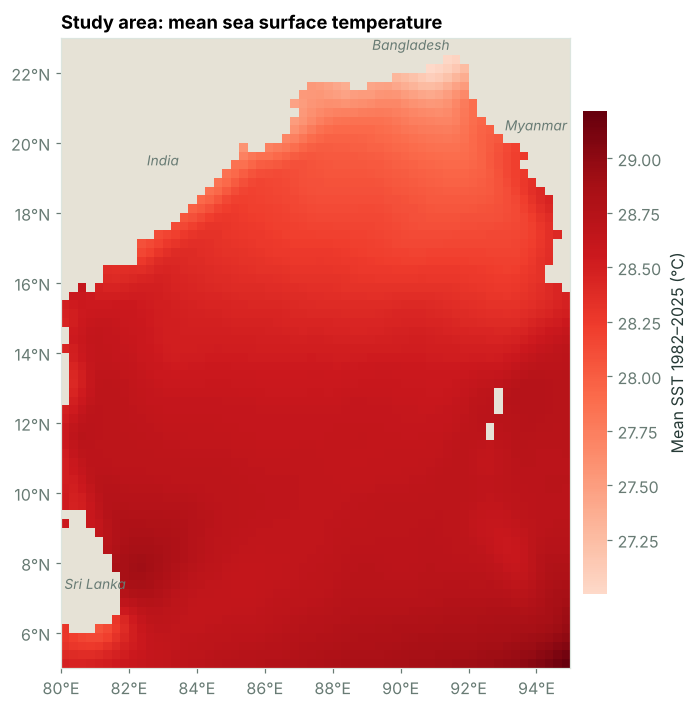

In [16]:
# 9f. Study area and mean SST
mean_map = sst.sel(time=sst.time.dt.year.isin(FULL_YEARS)).mean("time")
fig, ax = plt.subplots(figsize=(7.2, 7.6))
reds = plt.matplotlib.colors.ListedColormap(plt.cm.Reds(np.linspace(0.15, 1, 256)))  # keep the coolest water visible against land
mesh = ax.pcolormesh(mean_map.lon, mean_map.lat, mean_map, cmap=reds, shading="nearest")
map_axes(ax)
cb = fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.02)
cb.set_label(f"Mean SST {FIRST}–{LAST} (°C)")
cb.outline.set_visible(False)
ax.set_title("Study area: mean sea surface temperature")
save(fig, "sst_mean_map",
     "Map of the Bay of Bengal study area coloured by long-term mean SST",
     f"The study box ({LAT_MIN:.0f}–{LAT_MAX:.0f}°N, {LON_MIN:.0f}–{LON_MAX:.0f}°E) "
     f"with long-term mean SST. Land is shown in beige.")

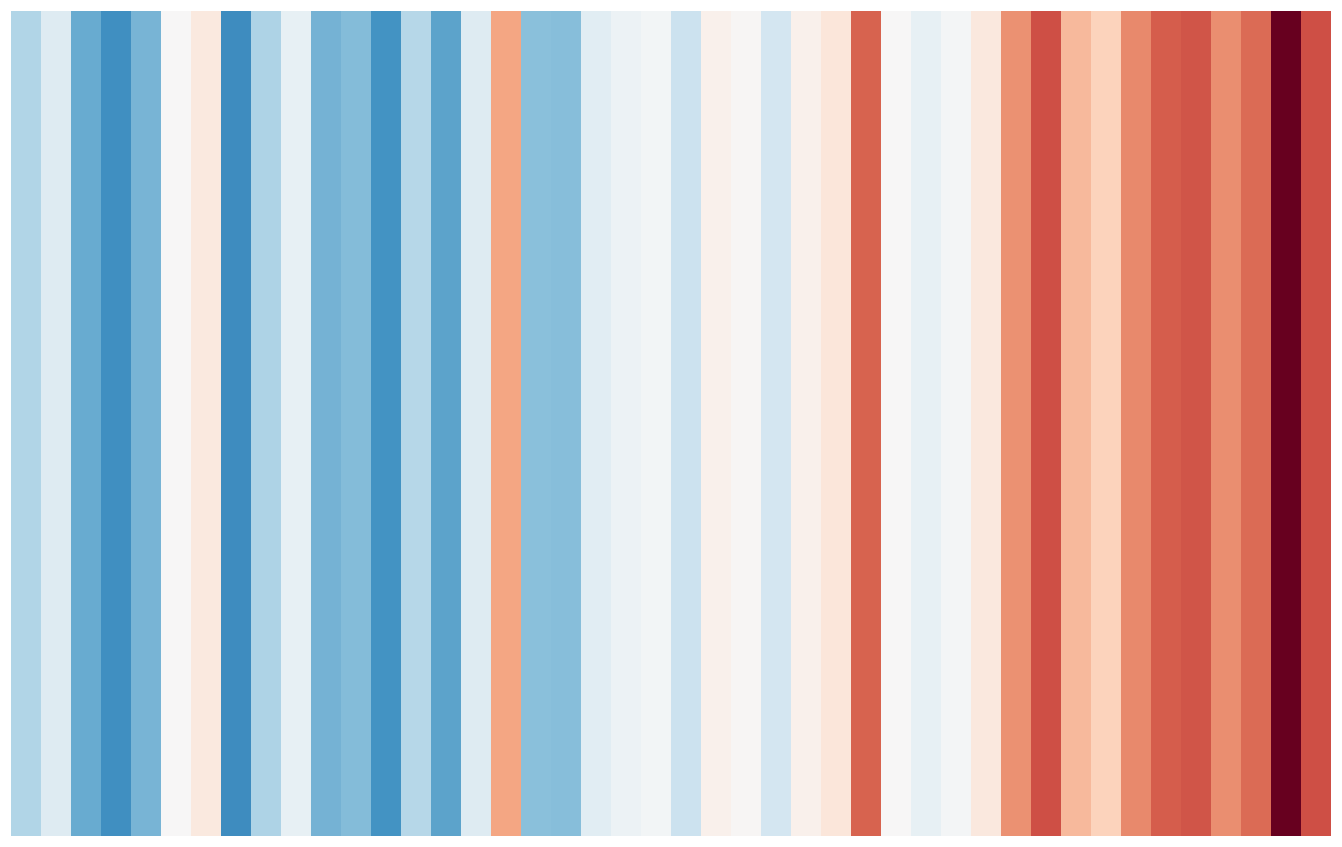

In [17]:
# 9g. Warming stripes thumbnail for the portfolio card (no axes)
lim = float(np.abs(annual_anom).max())
fig = plt.figure(figsize=(12, 7.5))
ax = fig.add_axes([0, 0, 1, 1])
ax.bar(annual_anom.index, 1, width=1, color=plt.cm.RdBu_r((annual_anom.values + lim) / (2 * lim)))
ax.set_xlim(annual_anom.index.min() - 0.5, annual_anom.index.max() + 0.5)
ax.set_ylim(0, 1)
ax.axis("off")
with plt.rc_context({"savefig.bbox": "standard"}):   # exact 1200 x 750 px, no padding
    fig.savefig(FIG_DIR / "thumbnail.png", dpi=100)
try:
    from PIL import Image
    Image.open(FIG_DIR / "thumbnail.png").convert("RGB").save(SITE_DIR / "figures" / "thumbnail.webp", "WEBP", quality=88)
except Exception:
    shutil.copy(FIG_DIR / "thumbnail.png", SITE_DIR / "figures" / "thumbnail.png")
shutil.copy(FIG_DIR / "thumbnail.png", SITE_DIR / "figures" / "social-preview.png")
plt.show()

## 10. Summary

The cell below writes the key numbers in plain sentences. These sentences are generated from the results, so they stay correct if the data or the study box changes.

In [18]:
sig_word = ("a statistically significant trend" if trend["mk_p"] < 0.05
            else "a trend that is not statistically significant at the 5% level")
direction = "warmed" if trend["sen_per_decade"] > 0 else "cooled"
fastest = season_trends["sen_per_decade"].idxmax()
slowest = season_trends["sen_per_decade"].idxmin()
warmest = annual.sort_values(ascending=False)
top5 = [int(y) for y in warmest.index[:5]]
recent_share = sum(y >= LAST - 9 for y in top5)

# Only call one season "fastest" if its confidence interval clears the slowest season's
fast, slow = season_trends.loc[fastest], season_trends.loc[slowest]
if fast["sen_low"] > slow["sen_high"]:
    season_sentence = (f"Warming was fastest in the {fastest.split(' (')[0].lower()} season "
                       f"({fast['sen_per_decade']:+.2f} °C/decade) and slowest in the "
                       f"{slowest.split(' (')[0].lower()} season ({slow['sen_per_decade']:+.2f} °C/decade).")
else:
    season_sentence = (f"All four seasons warmed at similar rates, from {slow['sen_per_decade']:+.2f} to "
                       f"{fast['sen_per_decade']:+.2f} °C/decade. The differences between seasons are "
                       f"smaller than their uncertainty, so no season stands out.")

sig_area = ("Every ocean grid cell in the study area" if sig_warming_pct >= 99.95
            else "Over 99% of the Bay's ocean area" if sig_warming_pct > 99
            else f"{sig_warming_pct:.0f}% of the Bay's ocean area")
recent_sentence = (f"All five of the warmest years fall in the last decade ({LAST - 9}–{LAST})."
                   if recent_share == 5 else
                   f"{recent_share} of the five warmest years fall in the last decade ({LAST - 9}–{LAST}).")

findings = [
    f"Between {FIRST} and {LAST}, the Bay of Bengal {direction} at about "
    f"{trend['sen_per_decade']:+.2f} °C per decade (95% CI {trend['sen_low']:+.2f} to "
    f"{trend['sen_high']:+.2f}), {sig_word} (Mann–Kendall {fmt_p(trend['mk_p'])}).",
    f"That adds up to roughly {total_change:+.2f} °C over the {N_YEARS}-year record.",
    f"The warmest year was {top5[0]} ({warmest.iloc[0]:.2f} °C basin average). {recent_sentence}",
    season_sentence,
    f"{sig_area} shows statistically significant warming. "
    f"The average trend is {north:+.2f} °C/decade north of 15°N and {south:+.2f} °C/decade south of it.",
]
for f in findings:
    print("•", f)

results = {
    "title": "How fast is the Bay of Bengal warming?",
    "region": {"lat": [LAT_MIN, LAT_MAX], "lon": [LON_MIN, LON_MAX]},
    "period": [FIRST, LAST], "n_years": N_YEARS, "baseline": [BASE_START, BASE_END],
    "mean_sst_c": round(float(basin.mean()), 3),
    "trend_annual": {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in trend.items()},
    "total_change_c": round(float(total_change), 3),
    "warmest_years": {int(y): round(float(v), 3) for y, v in warmest.head(5).items()},
    "season_trends": season_trends[["sen_per_decade", "sen_low", "sen_high", "mk_p", "n"]]
                     .round(4).to_dict(orient="index"),
    "spatial": {"min_trend": round(float(trend_map.min()), 3), "max_trend": round(float(trend_map.max()), 3),
                "significant_warming_area_pct": round(sig_warming_pct, 1),
                "north_of_15N": round(north, 3), "south_of_15N": round(south, 3)},
    "findings": findings,
    "data": {"dataset": "NOAA OI SST V2 High Resolution, monthly mean", "source": OPENDAP_URL,
             "accessed": ACCESS_DATE},
}
_ = (SITE_DIR / "results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False))

• Between 1982 and 2025, the Bay of Bengal warmed at about +0.20 °C per decade (95% CI +0.15 to +0.24), a statistically significant trend (Mann–Kendall p < 0.001).
• That adds up to roughly +0.87 °C over the 44-year record.
• The warmest year was 2024 (29.22 °C basin average). All five of the warmest years fall in the last decade (2016–2025).
• All four seasons warmed at similar rates, from +0.18 to +0.21 °C/decade. The differences between seasons are smaller than their uncertainty, so no season stands out.
• Every ocean grid cell in the study area shows statistically significant warming. The average trend is +0.20 °C/decade north of 15°N and +0.19 °C/decade south of it.


### Limitations

- **Short record.** About four decades of data is enough to detect a trend, but natural variability (El Niño–Southern Oscillation, the Indian Ocean Dipole) can make one decade look faster or slower than the long-term rate.
- **Autocorrelation.** Annual means reduce, but do not remove, year-to-year persistence, so the p-values are somewhat optimistic.
- **Surface only.** Satellite SST says nothing about warming below the surface, where the Bay's strong salinity stratification matters a lot.
- **Gridded product.** OISST blends satellite and in-situ data and smooths small features. Coastal cells near river mouths are the least reliable.

### Next steps

- Use the daily version of the dataset to count **marine heatwaves** with the Hobday et al. (2016) definition.
- Remove the ENSO and IOD signal with regression on their indices, to see how much of the trend remains.
- Compare with an independent dataset such as ERSST v5 or Argo float temperatures.

## 11. Export the project page for the website

This builds a standalone results page (`output/website/bay-of-bengal-sst/`) in the same style as my portfolio, with the numbers and figures from this run. Upload that folder to `projects/` in the website repository. This section is presentation only and does not change the analysis.

In [19]:
def fig_html(key):
    f = WEB_FIGS[key]
    return (f'<figure class="figure"><img src="{f["file"]}" alt="{f["alt"]}" width="{f["w"]}" '
            f'height="{f["h"]}" loading="lazy"><figcaption>{f["caption"]}</figcaption></figure>')


season_rows_html = "\n".join(
    f"<tr><td>{name}</td><td>{r.sen_per_decade:+.2f}</td>"
    f"<td>{r.sen_low:+.2f} to {r.sen_high:+.2f}</td><td>{fmt_p(r.mk_p)}</td></tr>"
    for name, r in season_trends.iterrows())

values = {
    "first": FIRST, "last": LAST, "n_years": N_YEARS,
    "base_start": BASE_START, "base_end": BASE_END,
    "rate": f"{trend['sen_per_decade']:+.2f}",
    "rate_ci": f"95% CI {trend['sen_low']:+.2f} to {trend['sen_high']:+.2f}",
    "total": f"{total_change:+.2f}",
    "warmest_year": top5[0],
    "warmest_note": (f"All 5 warmest years were in {LAST - 9}–{LAST}" if recent_share == 5
                     else f"{recent_share} of the 5 warmest years were in {LAST - 9}–{LAST}"),
    "findings": "\n".join(f"<li>{f}</li>" for f in findings),
    "fig_timeseries": fig_html("sst_anomaly_timeseries"),
    "fig_map": fig_html("sst_trend_map"),
    "fig_season": fig_html("sst_trend_by_season"),
    "fig_heatmap": fig_html("sst_anomaly_heatmap"),
    "fig_cycle": fig_html("sst_seasonal_cycle"),
    "fig_area": fig_html("sst_mean_map"),
    "season_rows": season_rows_html,
    "lat_min": f"{LAT_MIN:.0f}", "lat_max": f"{LAT_MAX:.0f}",
    "lon_min": f"{LON_MIN:.0f}", "lon_max": f"{LON_MAX:.0f}",
    "mk_p": fmt_p(trend["mk_p"]),
    "ols_rate": f"{trend['ols_per_decade']:+.2f}",
    "access_date": ACCESS_DATE,
    "github": GITHUB_REPO, "colab": COLAB_URL,
}

template = string.Template(Path("page_template.html").read_text(encoding="utf-8")) \
    if Path("page_template.html").exists() else None
if template is None:
    url = "https://raw.githubusercontent.com/ratulripon/bay-of-bengal-sst/main/page_template.html"
    template = string.Template(urllib.request.urlopen(url).read().decode("utf-8"))

_ = (SITE_DIR / "index.html").write_text(template.substitute(values), encoding="utf-8")
print("Website files:")
for p in sorted(SITE_DIR.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(OUT_DIR / "website"), f"{p.stat().st_size / 1024:.0f} KB")

if "google.colab" in sys.modules:
    archive = shutil.make_archive(str(OUT_DIR / "bay-of-bengal-sst-website"), "zip",
                                  OUT_DIR / "website")
    from google.colab import files
    files.download(archive)

Website files:
  bay-of-bengal-sst/data/bay_of_bengal_sst_monthly.csv 11 KB
  bay-of-bengal-sst/figures/social-preview.png 6 KB
  bay-of-bengal-sst/figures/sst_anomaly_heatmap.webp 58 KB
  bay-of-bengal-sst/figures/sst_anomaly_timeseries.webp 68 KB
  bay-of-bengal-sst/figures/sst_mean_map.webp 39 KB
  bay-of-bengal-sst/figures/sst_seasonal_cycle.webp 38 KB
  bay-of-bengal-sst/figures/sst_trend_by_season.webp 29 KB
  bay-of-bengal-sst/figures/sst_trend_map.webp 48 KB
  bay-of-bengal-sst/figures/thumbnail.webp 6 KB
  bay-of-bengal-sst/index.html 16 KB
  bay-of-bengal-sst/results.json 2 KB
